# EN4554 LoRA Module: Assignment 1 (Part 1: DoRA on a VLM, Part 2: Tool-calling agent)





## How to use this notebook (read this first)

1. **Runtime:** GPU (T4). On Kaggle choose *Accelerator = GPU T4* and *Internet = On*. On Colab: *Runtime, Change runtime type, T4 GPU*.
5. **Write the reports** from the tables/figures plus the *report scaffolds* (markdown cells) at the end of each part.

### Settings you may want to change (all in the settings cell)

| Setting | Default | Meaning |
|---|---|---|
| `SEEDS` | `[42]` | Add seeds (e.g. `[42, 43, 44]`) for mean ± std if time permits. |
| `RANKS` | `[4, 8, 16]` | LoRA/DoRA ranks to sweep (Part 1). Add `2` to stress the low-rank claim. |
| `N_TRAIN`, `N_EVAL` | 1000, 300 | ChartQA train / validation subset sizes. |
| `IMAGE_SPLITTING` | `False` | `True` = higher resolution, many more image tokens, much slower. |
| `RUN_BONUS` | `True` | Vision-specific bonus experiment (adapt text-only vs vision-only vs both). |
| `LLM_ID` | `Qwen/Qwen2.5-0.5B-Instruct` | Part 2 model. Needs a chat template that supports `tools=`. |
| `USE_DRIVE` | `False` | Colab only: save outputs to Google Drive so a disconnect is not fatal. |

---

## What each part does and how it maps to the assignment

### Part 1: Does DoRA's claim transfer from language to vision-language?

| Assignment step | Where in this notebook |
|---|---|
| 1. Choose a variant | **DoRA** (Liu et al., 2024), already implemented in `peft` via `use_dora=True` |
| 2. Choose a VLM | **SmolVLM-256M-Instruct** (≤ 500M) |
| 3. Hypothesis | markdown cell *"Claim and hypothesis"*. Edit it to say what **you** believe after reading the paper |
| 4. Dataset | **ChartQA** (HuggingFaceM4/ChartQA): `N_TRAIN` train examples, `N_EVAL` validation examples, both shuffled with a fixed seed |
| 5. Experiments | zero-shot baseline, then LoRA vs DoRA **rank sweep**, then a **magnitude/direction analysis** (ΔM, ΔD), then the **bonus** (vision vs text modules) |
| 6. Report | scaffold at the end of Part 1 |

**Why the metric is tied to the claim:** the claim is about *how DoRA compares to LoRA as capacity (rank) shrinks* and *how weights change* (magnitude vs direction). So the notebook reports accuracy **per rank**, the **paired DoRA − LoRA difference with a bootstrap confidence interval**, and the **ΔM–ΔD relationship**, not just one overall accuracy.
(Please re-read the DoRA paper's weight-decomposition analysis and low-rank experiments and make sure my paraphrase in the hypothesis cell matches what you cite.)

### Part 2: Tool-calling agent

| Assignment step | Where |
|---|---|
| 1. Minimal agent | 5 tools + `run_agent` loop (generate → parse → execute → feed back → stop) |
| 2. Data | template-generated train set (default 600) and a held-out test set (default 100) written with **disjoint phrasings**; includes no-tool requests, tool-lookalike no-tool requests, and two-call requests. An audit cell proves no leakage |
| 3. Baseline vs LoRA | call validity, call accuracy, abstention, task success, with the denominators printed; **assistant-only loss** |
| 4. Failure analysis | automatic categorisation of failures for every model + fixed / introduced / remaining analysis. Plus a **prompt-engineered baseline** so you can answer *"would a better prompt have been enough?"* with evidence |

---

## Deliverables checklist

- [ ] Part 1 report (≤ 3 pages): claim, translated hypothesis, setup, baseline vs adapted table/figure, interpretation
- [ ] Part 1 code: this notebook (it reproduces the main result)
- [ ] Part 2 write-up (≤ 1 page): setup, baseline-vs-LoRA table, failure analysis
- [ ] Part 2 code: this notebook (agent + training + evaluation)
- [ ] State the seed(s), split names and subset sizes (printed by the notebook)

## Troubleshooting

- **NaN loss:** lower `LR_P1` / `LR_P2` (fp16 on T4; bf16 is not supported in hardware).
- **CUDA out of memory:** lower `BATCH_P1` (raise `ACCUM_P1` to compensate) or `BATCH_P2`.
- **Hugging Face rate-limit warnings:** harmless; set an `HF_TOKEN` environment variable to remove them.
- **`dtype` / `torch_dtype` errors:** handled by `load_pretrained`; if you still see one, update `transformers`.
- **Template does not support tools** (Part 2): the notebook stops with a clear message. Use a model whose chat template renders `tools=` (Qwen2.5/Qwen3 do).
- **Session disconnected:** rerun all cells. Finished runs are loaded from `OUT_DIR/*.json`.

## 0. Setup

In [1]:
# Install / upgrade. On Colab you may be asked to restart the runtime after this cell. Do so, then continue.
!pip uninstall -y -q torchao
!pip install -q -U transformers peft datasets accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 91.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 34.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 35.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.


In [2]:
import os, sys, json, math, random, gc, time, re, ast, operator, warnings
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")      # Kaggle T4 x2: use one GPU only
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import set_seed

# =====================  SETTINGS  =====================


SEEDS      = [42]          # add more seeds for mean +- std, e.g. [42, 43, 44]
USE_DRIVE  = False         # Colab only: store outputs on Google Drive

# ---- Part 1 (vision-language) ----
VLM_ID          = "HuggingFaceTB/SmolVLM-256M-Instruct"
N_TRAIN, N_EVAL = 1000, 300
RANKS           = [4, 8, 16]
EPOCHS_P1       = 1
LR_P1           = 2e-4
BATCH_P1, ACCUM_P1 = 4, 2
EVAL_BS         = 8
IMAGE_SPLITTING = False    # True: higher resolution but far more image tokens (slow)
RUN_BONUS       = True     # vision-only vs text-only vs all modules
BONUS_RANK      = 8
MAX_NEW_TOKENS_P1 = 24

# ---- Part 2 (agent) ----
LLM_ID        = "Qwen/Qwen2.5-0.5B-Instruct"   # chat template must support tools=
N_TRAIN_P2    = 600
N_TEST_P2     = 100
EPOCHS_P2     = 2
LR_P2         = 2e-4
LORA_R_P2     = 16
LORA_ALPHA_P2 = 32
BATCH_P2, ACCUM_P2 = 4, 2
MAX_LEN_P2    = 1024
# ======================================================


SEED = SEEDS[0]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE  = torch.float16 if DEVICE == "cuda" else torch.float32   # T4: fp16, NOT bf16
if DEVICE == "cpu":
    print("WARNING: no GPU found. This will be extremely slow. Switch the runtime to a T4 GPU.")

# ---- output directory (+ optional Google Drive) ----
IN_COLAB = "google.colab" in sys.modules
OUT_DIR = "./outputs"
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/lora_module/" 
os.makedirs(OUT_DIR, exist_ok=True)

def save_json(obj, name):
    with open(os.path.join(OUT_DIR, name), "w") as f:
        json.dump(obj, f)

def load_json(name, default):
    p = os.path.join(OUT_DIR, name)
    return json.load(open(p)) if os.path.exists(p) else default

def free():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def load_pretrained(cls, model_id):
    # `dtype=` in new transformers, `torch_dtype=` in older ones.
    try:
        m = cls.from_pretrained(model_id, dtype=DTYPE)
    except TypeError:
        m = cls.from_pretrained(model_id, torch_dtype=DTYPE)
    return m.to(DEVICE)

set_seed(SEED)
print(f" seeds={SEEDS} | device={DEVICE} | dtype={DTYPE} | OUT_DIR={OUT_DIR}")


 seeds=[42] | device=cuda | dtype=torch.float16 | OUT_DIR=./outputs


# PART 1: Does a language-model LoRA variant's claim transfer to vision-language?

## Claim and hypothesis  *(edit this cell. It is the heart of your report)*

**Paper:** DoRA, *Weight-Decomposed Low-Rank Adaptation* (Liu et al., 2024).

**Central claim (paraphrase; verify against the paper):** Decomposing a pretrained weight into a *magnitude* and a *direction*, and adapting the direction with LoRA while learning the magnitude separately, lets low-rank tuning behave more like full fine-tuning and outperform LoRA, notably at *low ranks*, on language tasks.

**Concept chosen for translation:** (a) *DoRA's advantage over LoRA is larger at low rank*, and (b) the *mechanism*: LoRA couples magnitude and direction updates, DoRA decouples them.

**Translated hypotheses (vision-language, ChartQA, SmolVLM-256M):**

- **H1 (performance):** On ChartQA, DoRA achieves higher relaxed accuracy than LoRA at low rank (r = 4, 8), and the DoRA − LoRA gap shrinks as rank grows.
- **H2 (mechanism):** In the adapted weights, the relationship between magnitude change ΔM and direction change ΔD differs between LoRA and DoRA (DoRA's is less positively coupled, closer to the pattern the paper reports for full fine-tuning).
- **H3 (bonus, vision-specific):** The benefit of decoupling magnitude/direction differs between the *vision encoder* and the *language decoder* modules.

**What would falsify them:** a DoRA − LoRA paired-bootstrap 95% CI that includes 0 at every rank (H1); no difference in the ΔM–ΔD relation between methods (H2).

## 1.1 Data: ChartQA subset

ChartQA is chart question answering (OCR-and-reasoning heavy). We take a **seeded random** subset (not the first-N rows, which can be biased) of the `train` split for training and of the `val` split for evaluation.

In [3]:
from datasets import load_dataset
from torch.utils.data import Dataset

raw_train = load_dataset("HuggingFaceM4/ChartQA", split="train")   # first call downloads ~1 GB
raw_val   = load_dataset("HuggingFaceM4/ChartQA", split="val")
print(raw_train.features)

train_hf = raw_train.shuffle(seed=SEED).select(range(N_TRAIN))
eval_hf  = raw_val.shuffle(seed=SEED).select(range(N_EVAL))

class VQAExamples(Dataset):
    """Normalises the dataset rows to {image, question, answers, src}."""
    def __init__(self, hf): self.hf = hf
    def __len__(self): return len(self.hf)
    def __getitem__(self, i):
        r = self.hf[i]
        ans = r.get("label", r.get("answer"))
        answers = [str(a) for a in ans] if isinstance(ans, (list, tuple)) else [str(ans)]
        return {"image": r["image"].convert("RGB"),
                "question": r.get("query", r.get("question")),
                "answers": answers,
                "src": r.get("human_or_machine", -1)}   # 0 = human-written, 1 = machine-generated

train_ds = VQAExamples(train_hf)
eval_ds  = VQAExamples(eval_hf)
print(f"train subset: {len(train_ds)} (split='train', shuffled seed={SEED}) | eval subset: {len(eval_ds)} (split='val', shuffled seed={SEED})")
ex = eval_ds[0]; print(ex["question"], "->", ex["answers"])

README.md:   0%|          | 0.00/852 [00:00<?, ?B/s]

data/train-00000-of-00003-49492f364babfa(…): reconstructing file:   0%|          |  0.00B /  219MB            

data/train-00000-of-00003-49492f364babfa(…): downloading bytes:           |  0.00B            

data/train-00001-of-00003-7302bae5e425bb(…): reconstructing file:   0%|          |  0.00B /  311MB            

data/train-00001-of-00003-7302bae5e425bb(…): downloading bytes:           |  0.00B            

...

data/test-00000-of-00001-e2cd0b7a0f9eb20(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/28299 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1920 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2500 [00:00<?, ? examples/s]

{'image': Image(mode=None, decode=True), 'query': Value('string'), 'label': List(Value('string')), 'human_or_machine': ClassLabel(names=['human', 'machine'])}
train subset: 1000 (split='train', shuffled seed=42) | eval subset: 300 (split='val', shuffled seed=42)
What was the value of the pizza delivery market in the UK at the end of 2017? -> ['6.2']


## 1.2 Model, prompt, and the training collator (**loss on the answer tokens only**)

The original notebook set `labels = input_ids`, so the model was also trained to reproduce the prompt and the image placeholder tokens. Here we mask everything except the answer.

In [4]:
from transformers import AutoProcessor
try:
    from transformers import AutoModelForImageTextToText as VLMClass
except ImportError:
    from transformers import Idefics3ForConditionalGeneration as VLMClass
from peft import LoraConfig, get_peft_model

processor = AutoProcessor.from_pretrained(VLM_ID)
processor.image_processor.do_image_splitting = IMAGE_SPLITTING   # False = far fewer image tokens

PROMPT = "{q}\nAnswer with a single word or number."   # same prompt for train and eval

def user_msg(q):
    return [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT.format(q=q)}]}]

def full_msgs(q, a):
    return user_msg(q) + [{"role": "assistant", "content": [{"type": "text", "text": a}]}]

class VQACollator:
    """Builds a padded batch and masks every token except the assistant's answer with -100."""
    def __call__(self, batch):
        processor.tokenizer.padding_side = "right"
        imgs  = [[b["image"]] for b in batch]
        fulls = [processor.apply_chat_template(full_msgs(b["question"], b["answers"][0]), tokenize=False) for b in batch]
        proms = [processor.apply_chat_template(user_msg(b["question"]), add_generation_prompt=True, tokenize=False) for b in batch]
        enc = processor(text=fulls, images=imgs, return_tensors="pt", padding=True)
        labels = enc["input_ids"].clone()
        labels[enc["attention_mask"] == 0] = -100
        for i in range(len(batch)):
            plen = processor(text=[proms[i]], images=[imgs[i]], return_tensors="pt")["input_ids"].shape[1]
            labels[i, :plen] = -100
        enc["labels"] = labels
        return dict(enc)

# ---- sanity check: only the answer should be supervised ----
_b = VQACollator()([train_ds[0], train_ds[1]])
for i in range(2):
    sup = _b["labels"][i][_b["labels"][i] != -100]
    print(f"[check {i}] supervised tokens decode to: {processor.tokenizer.decode(sup)!r}  (expected answer: {train_ds[i]['answers'][0]!r})")
print("pixel_values shape:", tuple(_b["pixel_values"].shape), "| seq len:", _b["input_ids"].shape[1])
del _b

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.2k [00:00<?, ?B/s]

...

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.74k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.55M [00:00<?, ?B/s]

[check 0] supervised tokens decode to: ' 36<end_of_utterance>\n'  (expected answer: '36')
[check 1] supervised tokens decode to: ' Yes<end_of_utterance>\n'  (expected answer: 'Yes')
pixel_values shape: (2, 1, 3, 512, 512) | seq len: 101


## 1.3 Metric: ChartQA *relaxed accuracy*

Standard ChartQA metric: for numeric answers a prediction is correct if it is within **5%** of the target; otherwise an exact (case-insensitive) string match is required. **One deliberate deviation:** four-digit answers (years) must match exactly, because a 5% tolerance would accept 2008 for 2018. State this in your report. (The original notebook had no principled rule: "0.72" vs "72" and "2018" vs "2008" are both wrong answers.) We also report accuracy for **human-written** vs **machine-generated** questions, since they differ in difficulty.

In [5]:
def _to_float(s):
    s = str(s).strip().replace(",", "").replace("$", "")
    pct = s.endswith("%")
    s = s.rstrip("%").strip()
    try:
        return float(s)
    except ValueError:
        return None

def relaxed_correct(pred, answers, tol=0.05):
    p = str(pred).strip()
    for a in answers:
        a = str(a).strip()
        pf, af = _to_float(p), _to_float(a)
        if re.fullmatch(r"\d{4}", p) and re.fullmatch(r"\d{4}", a):    # years: exact match (5% tolerance would accept 2008 for 2018)
            if p == a: return True
        elif pf is not None and af is not None:
            if af == 0:
                if pf == 0: return True
            elif abs(pf - af) / abs(af) <= tol:
                return True
        elif p.lower() == a.lower():
            return True
    return False

assert relaxed_correct("0.72", ["0.72"]) and relaxed_correct("71", ["72"]) and not relaxed_correct("72", ["0.72"])
assert relaxed_correct("Blue", ["blue"]) and not relaxed_correct("2008", ["2018"])

@torch.no_grad()
def evaluate_vqa(model, ds, bs=EVAL_BS, desc="eval"):
    model.eval()
    processor.tokenizer.padding_side = "left"
    preds = []
    for i in tqdm(range(0, len(ds), bs), desc=desc, leave=False):
        batch = [ds[j] for j in range(i, min(i + bs, len(ds)))]
        prompts = [processor.apply_chat_template(user_msg(b["question"]), add_generation_prompt=True, tokenize=False) for b in batch]
        enc = processor(text=prompts, images=[[b["image"]] for b in batch], return_tensors="pt", padding=True).to(DEVICE)
        enc["pixel_values"] = enc["pixel_values"].to(DTYPE)
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS_P1, do_sample=False)
        preds += [t.strip() for t in processor.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)]
    correct = [int(relaxed_correct(p, ds[k]["answers"])) for k, p in enumerate(preds)]
    srcs = [ds[k]["src"] for k in range(len(ds))]
    def acc(mask): 
        sel = [c for c, m in zip(correct, mask) if m]
        return float(np.mean(sel)) if sel else float("nan")
    return {"acc": float(np.mean(correct)),
            "acc_human": acc([s == 0 for s in srcs]),
            "acc_machine": acc([s == 1 for s in srcs]),
            "correct": correct, "preds": preds}

## 1.4 Zero-shot baseline (no adaptation)

In [6]:
RESULTS  = load_json("results_p1.json", {})     # key -> record (cached across sessions)
ANALYSIS = load_json("analysis_p1.json", {})    # key -> per-module magnitude/direction rows

def zs_key(seed): return f"zeroshot_s{seed}"
if zs_key(SEED) not in RESULTS:
    free(); set_seed(SEED)
    base = load_pretrained(VLMClass, VLM_ID)
    r = evaluate_vqa(base, eval_ds, desc="zero-shot")
    RESULTS[zs_key(SEED)] = {"key": zs_key(SEED), "method": "zero-shot", "rank": 0, "scope": "-", "seed": SEED,
                             "trainable_params": 0, "train_loss": float("nan"), "train_time_s": 0.0, **r}
    save_json(RESULTS, "results_p1.json")
    del base; free()
z = RESULTS[zs_key(SEED)]
print(f"Zero-shot relaxed accuracy: {z['acc']:.3f}  (human {z['acc_human']:.3f} | machine {z['acc_machine']:.3f})")
print("sample predictions:", list(zip(z["preds"][:5], [eval_ds[i]["answers"][0] for i in range(5)])))

model.safetensors: reconstructing file:   0%|          |  0.00B /  513MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

zero-shot:   0%|          | 0/38 [00:00<?, ?it/s]

Zero-shot relaxed accuracy: 0.063  (human 0.089 | machine 0.035)
sample predictions: [('6.6 million.', '6.2'), ('62.', '9'), ('Yes.', 'No'), ('1.5.', '1.74'), ('13.', '1')]


## 1.5 LoRA / DoRA experiment function

- `scope` chooses *which modules* get adapters: `"all"` (main experiment), or `"text"` / `"vision"` (bonus). Module names are discovered from the model itself (no brittle hard-coded names), and the multimodal connector and `lm_head` are never adapted.
- LoRA and DoRA share **identical** hyperparameters (`alpha = 2 x r`, same LR, data order via the same seed). The *only* difference is `use_dora`.
- `weight_delta_analysis` measures how much each adapted weight changed in **magnitude** (ΔM) and **direction** (ΔD) relative to the pretrained weight, computed analytically in fp32 from the adapter weights (so fp16 rounding cannot swamp the tiny changes). It follows the paper's definitions, using per-output-row norms as in `peft`'s DoRA implementation.

In [7]:
from transformers import TrainingArguments, Trainer

LINEAR_LEAVES = {"q_proj", "k_proj", "v_proj", "o_proj", "out_proj", "gate_proj", "up_proj", "down_proj", "fc1", "fc2"}

def find_targets(model, scope):
    names = []
    for n, m in model.named_modules():
        if not isinstance(m, torch.nn.Linear) or "lm_head" in n or "connector" in n:
            continue
        if n.split(".")[-1] not in LINEAR_LEAVES:
            continue
        is_vision = "vision" in n
        if scope == "all" or (scope == "vision" and is_vision) or (scope == "text" and not is_vision):
            names.append(n)
    return names

@torch.no_grad()
def weight_delta_analysis(peft_model):
    rows = []
    for name, mod in peft_model.named_modules():
        if hasattr(mod, "lora_A") and "default" in mod.lora_A:
            W0 = mod.base_layer.weight.float()
            A  = mod.lora_A["default"].weight.float()
            B  = mod.lora_B["default"].weight.float()
            V  = W0 + mod.scaling["default"] * (B @ A)             # direction part (un-normalised)
            n0 = W0.norm(dim=1)                                    # pretrained per-row magnitude
            if hasattr(mod, "lora_magnitude_vector") and "default" in mod.lora_magnitude_vector:
                mv = mod.lora_magnitude_vector["default"]
                m = (mv.weight if hasattr(mv, "weight") else mv).float()   # DoRA: learned magnitude
            else:
                m = V.norm(dim=1)                                  # LoRA: magnitude is whatever results
            dM = (m - n0).abs().mean().item()
            dD = (1 - torch.nn.functional.cosine_similarity(V, W0, dim=1)).mean().item()
            rows.append({"module": name, "group": "vision" if "vision" in name else "text",
                         "dM": dM, "dD": dD, "dM_rel": ((m - n0).abs() / n0).mean().item()})
    return rows

def run_experiment(method, rank, scope="all", seed=SEED):
    assert method in ("lora", "dora")
    key = f"{method}_r{rank}_{scope}_s{seed}"
    if key in RESULTS:
        print(f"[cached] {key}: acc={RESULTS[key]['acc']:.3f}"); return RESULTS[key]
    free(); set_seed(seed)
    base = load_pretrained(VLMClass, VLM_ID)
    targets = find_targets(base, scope)
    cfg = LoraConfig(r=rank, lora_alpha=2 * rank, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                     target_modules=targets, use_dora=(method == "dora"))
    model = get_peft_model(base, cfg)
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n=== {key} | {len(targets)} adapted modules | trainable params {n_train:,} ===")
    args = TrainingArguments(
        output_dir=os.path.join(OUT_DIR, f"tmp_{key}"), per_device_train_batch_size=BATCH_P1,
        gradient_accumulation_steps=ACCUM_P1, learning_rate=LR_P1, num_train_epochs=EPOCHS_P1,
        lr_scheduler_type="cosine", warmup_steps=5, fp16=(DEVICE == "cuda"), logging_steps=10,
        save_strategy="no", report_to="none", remove_unused_columns=False, dataloader_num_workers=0,
        seed=seed, label_names=["labels"])
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, data_collator=VQACollator())
    t0 = time.time(); out = trainer.train(); dt = time.time() - t0
    ANALYSIS[key] = weight_delta_analysis(model)
    r = evaluate_vqa(model, eval_ds, desc=f"eval {key}")
    model.save_pretrained(os.path.join(OUT_DIR, f"adapter_{key}"))
    RESULTS[key] = {"key": key, "method": method, "rank": rank, "scope": scope, "seed": seed,
                    "trainable_params": n_train, "train_loss": float(out.training_loss), "train_time_s": dt, **r}
    save_json(RESULTS, "results_p1.json"); save_json(ANALYSIS, "analysis_p1.json")
    print(f"{key}: acc={r['acc']:.3f} (human {r['acc_human']:.3f} | machine {r['acc_machine']:.3f}) | train loss {out.training_loss:.3f} | {dt/60:.1f} min")
    del trainer, model, base; free()
    return RESULTS[key]

## 1.6 Run the rank sweep (LoRA vs DoRA) and the bonus experiment

Finished runs are cached to `results_p1.json`, so a disconnect only costs you the run in progress.

In [8]:
for seed in SEEDS:
    for rank in RANKS:
        for method in ("lora", "dora"):
            run_experiment(method, rank, "all", seed)

if RUN_BONUS:                       # vision-specific: where should the adapters go?
    for seed in SEEDS:
        for scope in ("text", "vision"):
            for method in ("lora", "dora"):
                run_experiment(method, BONUS_RANK, scope, seed)

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]


=== lora_r4_all_s42 | 282 adapted modules | trainable params 1,884,672 ===


Step,Training Loss
10,3.969835
20,1.453292
30,1.008257
40,0.895041
50,0.859588
60,0.775078
70,0.725261
80,0.743482
90,0.634422
100,0.721480


eval lora_r4_all_s42:   0%|          | 0/38 [00:00<?, ?it/s]

lora_r4_all_s42: acc=0.317 (human 0.253 | machine 0.387) | train loss 1.077 | 7.1 min


...

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]


=== dora_r8_vision_s42 | 72 adapted modules | trainable params 1,410,048 ===


Step,Training Loss
10,4.266736
20,2.176951
30,1.378103
40,1.101438
50,0.937523
60,0.858662
70,0.787242
80,0.800076
90,0.689956
100,0.784962


eval dora_r8_vision_s42:   0%|          | 0/38 [00:00<?, ?it/s]

dora_r8_vision_s42: acc=0.293 (human 0.190 | machine 0.408) | train loss 1.252 | 7.4 min


## 1.7 Results: baseline vs adapted, tied to the claim

Outputs: the summary table, the accuracy-vs-rank figure, and the **paired bootstrap** of (DoRA − LoRA) at each rank. With ~300 eval questions the standard error of one accuracy is about ±2.5 points, so a raw gap of 1 to 2 points is **not** evidence. The bootstrap CI says whether it is.

ChartQA val subset: n=300 | metric: relaxed accuracy (5% tolerance) | seeds=[42]
   method  scope  rank  trainable_params    acc  acc_std  acc_human  acc_machine  train_loss  n_seeds
     dora    all     4           2123136 0.3133      NaN     0.2405       0.3944      1.0334        1
     dora    all     8           4007808 0.3367      NaN     0.2468       0.4366      0.9617        1
     dora    all    16           7777152 0.3633      NaN     0.2722       0.4648      0.8990        1
     dora   text     8           2597760 0.3000      NaN     0.1962       0.4155      1.1015        1
     dora vision     8           1410048 0.2933      NaN     0.1899       0.4085      1.2522        1
     lora    all     4           1884672 0.3167      NaN     0.2532       0.3873      1.0772        1
     lora    all     8           3769344 0.3533      NaN     0.2848       0.4296      0.9761        1
     lora    all    16           7538688 0.3567      NaN     0.2911       0.4296      0.9015        1
 

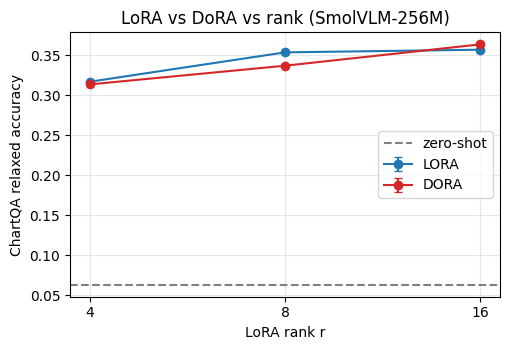


Paired bootstrap, DoRA - LoRA (accuracy points), 95% CI:
  r=  4: -0.3 pts  [-3.0, +2.3]  -> inconclusive (CI includes 0)
  r=  8: -1.7 pts  [-5.0, +1.7]  -> inconclusive (CI includes 0)
  r= 16: +0.7 pts  [-4.3, +5.3]  -> inconclusive (CI includes 0)


In [9]:

df = pd.DataFrame(list(RESULTS.values()))
summary = (df.groupby(["method", "scope", "rank"])
             .agg(acc=("acc", "mean"), acc_std=("acc", "std"), acc_human=("acc_human", "mean"),
                  acc_machine=("acc_machine", "mean"), trainable_params=("trainable_params", "first"),
                  train_loss=("train_loss", "mean"), n_seeds=("seed", "count")).reset_index())
display_cols = ["method", "scope", "rank", "trainable_params", "acc", "acc_std", "acc_human", "acc_machine", "train_loss", "n_seeds"]
print(f"ChartQA val subset: n={N_EVAL} | metric: relaxed accuracy (5% tolerance) | seeds={SEEDS}")
print(summary[display_cols].round(4).to_string(index=False))
summary.to_csv(os.path.join(OUT_DIR, "summary_p1.csv"), index=False)

# ---- accuracy vs rank ----
main = summary[(summary.scope == "all") & summary.method.isin(["lora", "dora"])]
zs = summary[summary.method == "zero-shot"]["acc"].iloc[0]
fig, ax = plt.subplots(figsize=(5.2, 3.6))
for m, c in (("lora", "tab:blue"), ("dora", "tab:red")):
    d = main[main.method == m].sort_values("rank")
    ax.errorbar(d["rank"], d["acc"], yerr=d["acc_std"].fillna(0), marker="o", label=m.upper(), color=c, capsize=3)
ax.axhline(zs, ls="--", color="gray", label="zero-shot")
ax.set_xscale("log", base=2); ax.set_xticks(sorted(main["rank"].unique())); ax.set_xticklabels(sorted(main["rank"].unique()))
ax.set_xlabel("LoRA rank r"); ax.set_ylabel("ChartQA relaxed accuracy"); ax.set_title("LoRA vs DoRA vs rank (SmolVLM-256M)")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig_acc_vs_rank.png"), dpi=200); plt.show()

# ---- paired bootstrap of DoRA - LoRA ----
def paired_bootstrap(a, b, n=5000, seed=0):
    rng = np.random.default_rng(seed); a, b = np.asarray(a, float), np.asarray(b, float)
    idx = rng.integers(0, len(a), (n, len(a)))
    d = (b[idx] - a[idx]).mean(1)
    return float((b - a).mean()), np.percentile(d, [2.5, 97.5])

def mean_correct(method, rank, scope="all"):
    arrs = [np.array(r["correct"]) for r in RESULTS.values() if r["method"] == method and r["rank"] == rank and r["scope"] == scope]
    return np.mean(arrs, axis=0) if arrs else None

print("\nPaired bootstrap, DoRA - LoRA (accuracy points), 95% CI:")
rows = []
for rank in sorted(main["rank"].unique()):
    a, b = mean_correct("lora", rank), mean_correct("dora", rank)
    if a is None or b is None: continue
    d, (lo, hi) = paired_bootstrap(a, b)
    verdict = "DoRA better" if lo > 0 else ("LoRA better" if hi < 0 else "inconclusive (CI includes 0)")
    rows.append({"rank": rank, "dora_minus_lora": d, "ci_low": lo, "ci_high": hi, "verdict": verdict})
    print(f"  r={rank:>3}: {d*100:+.1f} pts  [{lo*100:+.1f}, {hi*100:+.1f}]  -> {verdict}")
pd.DataFrame(rows).to_csv(os.path.join(OUT_DIR, "bootstrap_dora_minus_lora.csv"), index=False)

## 1.8 Mechanism analysis (H2): magnitude change ΔM vs direction change ΔD

For every adapted weight matrix, ΔM = mean |m_adapted − m_pretrained| and ΔD = mean (1 − cos(V_adapted, V_pretrained)) over output rows. Plot ΔM against ΔD for LoRA and DoRA and compare the correlation. (The paper reports that full fine-tuning shows a different ΔM–ΔD relation from LoRA, and that DoRA's resembles full fine-tuning. Check the figure in the paper and state whether yours agrees. **Do not claim agreement or disagreement before looking at your own plot.**) Modules are coloured by *vision encoder* vs *language decoder*, which is the vision-specific angle.

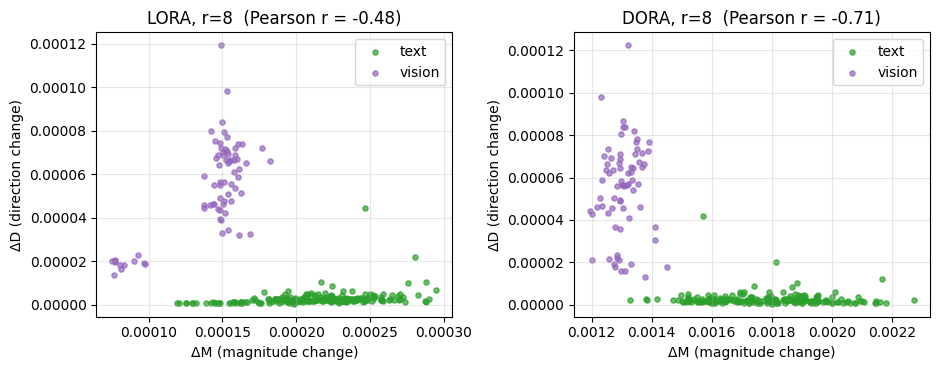

method  corr_all  corr_text  corr_vision  mean_dD_text  mean_dD_vision  mean_dM_text  mean_dM_vision
  lora  -0.47844    0.30589      0.70973           0.0         0.00005       0.00021         0.00014
  dora  -0.71001   -0.05396      0.06541           0.0         0.00005       0.00178         0.00130


In [10]:
ana_rank = BONUS_RANK if BONUS_RANK in RANKS else RANKS[-1]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharex=False, sharey=False)
corr_rows = []
for ax, method in zip(axes, ("lora", "dora")):
    key = f"{method}_r{ana_rank}_all_s{SEED}"
    if key not in ANALYSIS: ax.set_title(f"{method.upper()} (missing)"); continue
    a = pd.DataFrame(ANALYSIS[key])
    for g, c in (("text", "tab:green"), ("vision", "tab:purple")):
        s = a[a.group == g]; ax.scatter(s.dM, s.dD, s=14, alpha=.7, c=c, label=g)
    r_all = np.corrcoef(a.dM, a.dD)[0, 1]
    ax.set_title(f"{method.upper()}, r={ana_rank}  (Pearson r = {r_all:.2f})")
    ax.set_xlabel("ΔM (magnitude change)"); ax.set_ylabel("ΔD (direction change)"); ax.grid(alpha=.3); ax.legend()
    corr_rows.append({"method": method, "corr_all": r_all,
                      **{f"corr_{g}": np.corrcoef(a[a.group == g].dM, a[a.group == g].dD)[0, 1] for g in ("text", "vision") if (a.group == g).sum() > 2},
                      "mean_dD_text": a[a.group == "text"].dD.mean(), "mean_dD_vision": a[a.group == "vision"].dD.mean(),
                      "mean_dM_text": a[a.group == "text"].dM.mean(), "mean_dM_vision": a[a.group == "vision"].dM.mean()})
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_dM_vs_dD.png"), dpi=200); plt.show()
corr_df = pd.DataFrame(corr_rows); print(corr_df.round(5).to_string(index=False))
corr_df.to_csv(os.path.join(OUT_DIR, "mag_dir_correlations.csv"), index=False)

## 1.9 Bonus (H3): where should adapters go in a VLM?

A uniquely multimodal question: adapt only the **language decoder** (`text`), only the **vision encoder** (`vision`), or **everything** (`all`). Compare LoRA vs DoRA in each setting at `BONUS_RANK`.

In [11]:
b = summary[(summary["rank"] == BONUS_RANK) & summary.method.isin(["lora", "dora"])]
if RUN_BONUS and len(b):
    print(b[["method", "scope", "trainable_params", "acc", "acc_human", "acc_machine"]].round(4).sort_values(["scope", "method"]).to_string(index=False))
    for scope in ("text", "vision", "all"):
        a, bb = mean_correct("lora", BONUS_RANK, scope), mean_correct("dora", BONUS_RANK, scope)
        if a is not None and bb is not None:
            d, (lo, hi) = paired_bootstrap(a, bb)
            print(f"  scope={scope:<6} DoRA - LoRA = {d*100:+.1f} pts  [{lo*100:+.1f}, {hi*100:+.1f}]")
else:
    print("Bonus experiment not run (RUN_BONUS=False).")

method  scope  trainable_params    acc  acc_human  acc_machine
  dora    all           4007808 0.3367     0.2468       0.4366
  lora    all           3769344 0.3533     0.2848       0.4296
  dora   text           2597760 0.3000     0.1962       0.4155
  lora   text           2442240 0.3000     0.1962       0.4155
  dora vision           1410048 0.2933     0.1899       0.4085
  lora vision           1327104 0.2900     0.2152       0.3732
  scope=text   DoRA - LoRA = +0.0 pts  [-1.3, +1.3]
  scope=vision DoRA - LoRA = +0.3 pts  [-2.7, +3.3]
  scope=all    DoRA - LoRA = -1.7 pts  [-5.0, +1.7]


## 1.10 Qualitative examples (for the interpretation section)

In [12]:
lo_k, do_k = f"lora_r{RANKS[0]}_all_s{SEED}", f"dora_r{RANKS[0]}_all_s{SEED}"
rows = []
for i in range(min(12, len(eval_ds))):
    rows.append({"question": eval_ds[i]["question"][:70], "gt": eval_ds[i]["answers"][0],
                 "zero-shot": RESULTS[zs_key(SEED)]["preds"][i],
                 f"LoRA r={RANKS[0]}": RESULTS[lo_k]["preds"][i] if lo_k in RESULTS else "-",
                 f"DoRA r={RANKS[0]}": RESULTS[do_k]["preds"][i] if do_k in RESULTS else "-"})
pd.set_option("display.width", 200); print(pd.DataFrame(rows).to_string(index=False))

                                                              question          gt                                                                                     zero-shot   LoRA r=4     DoRA r=4
What was the value of the pizza delivery market in the UK at the end o         6.2                                                                                  6.6 million.        2.1          2.1
                                What is the smallest value represented           9                                                                                           62.         62            1
                   Is Croatia global hunger index extremely alarminhg?          No                                                                                          Yes.        Yes          Yes
                             What was Russia's fertility rate in 2020?        1.74                                                                                          1.5.       1.41         

## Part 1 report scaffold (≤ 3 pages). Fill with **your** numbers

1. **Central claim of DoRA** (1 to 2 sentences): …
2. **Concept translated + supporting evidence in the paper:** (cite the paper's table/figure on low-rank robustness and/or the ΔM–ΔD analysis) …
3. **Translated hypothesis:** H1/H2/(H3) from the cell above, stated precisely, with what would falsify it.
4. **Setup:** SmolVLM-256M-Instruct; ChartQA (`train` subset N_TRAIN=…, `val` subset N_EVAL=…, shuffled with seed …); relaxed accuracy; LoRA and DoRA identical except `use_dora`; `alpha=2r`, dropout 0.05, LR …, epochs …, fp16, loss on answer tokens only; image splitting …; adapters on …; seed(s) …
5. **Results:** table `summary_p1.csv` + `fig_acc_vs_rank.png` (zero-shot vs LoRA vs DoRA per rank), bootstrap CIs `bootstrap_dora_minus_lora.csv`, `fig_dM_vs_dD.png`, bonus table.
6. **Interpretation:** does H1 hold (CI excludes 0? at which ranks)? does H2 match the paper's pattern? Is the effect different for vision vs text modules? Be explicit about limits (small model, small subset, single seed, short training, 5% relaxed metric) and say whether your evidence *supports, contradicts, or fails to resolve* the claim.

# PART 2: A minimal tool-calling agent, and what LoRA changes

**Plan:** build the agent → generate train/test data (disjoint phrasings) → evaluate the untouched model → evaluate a *prompt-engineered* version of the untouched model → LoRA-finetune (assistant-only loss) → evaluate → analyse failures.

**What was fixed relative to the original notebook (so you can explain it in the write-up):**

1. The agent loop now returns a **trace** (every call, result, and the final answer). Previously it returned only the final text, so "call validity" looked for a `<tool_call>` in text that never contains one (hence 0%).
2. **Task success** checks that the final answer contains the correct value. It was "output is non-empty".
3. **One format everywhere:** training and inference both use the model's **native chat template with `tools=`**, so there is no train/inference prompt mismatch.
4. Training includes the full loop (`user → tool call → tool result → final answer`) with **loss only on assistant turns** (the old collator silently recomputed labels over every token).
5. Test phrasings are **disjoint** from train phrasings (audited in code). No-tool requests are varied and include tool-lookalike questions.
6. A **baseline was measured before** LoRA, plus a prompt-only baseline, which is the evidence needed for the "better prompt?" question.

## 2.1 Tools (5 tools with made-up data, so the model *must* call them)

In [13]:
# ---------------- 5 tools ----------------
_BIN = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv}

def safe_eval(expr):
    def ev(n):
        if isinstance(n, ast.Expression): return ev(n.body)
        if isinstance(n, ast.Constant) and isinstance(n.value, (int, float)) and not isinstance(n.value, bool): return n.value
        if isinstance(n, ast.BinOp) and type(n.op) in _BIN: return _BIN[type(n.op)](ev(n.left), ev(n.right))
        if isinstance(n, ast.UnaryOp) and isinstance(n.op, (ast.USub, ast.UAdd)):
            return -ev(n.operand) if isinstance(n.op, ast.USub) else ev(n.operand)
        raise ValueError("unsupported expression")
    return ev(ast.parse(str(expr).strip(), mode="eval"))

def fmt_num(x):
    if isinstance(x, float):
        x = round(x, 4)
        if x == int(x): x = int(x)
    return str(x)

def calculator(expression: str) -> str:
    try:
        return fmt_num(safe_eval(expression))
    except ZeroDivisionError:
        return "Error: division by zero"
    except Exception:
        return "Error: invalid expression"

WEATHER = {"colombo": (31, "humid with scattered thunderstorms"), "london": (12, "overcast and drizzly"),
           "tokyo": (19, "clear with a light breeze"), "new york": (23, "sunny"), "paris": (15, "cloudy"),
           "sydney": (26, "hot and windy"), "nairobi": (22, "partly cloudy"), "lima": (18, "foggy")}

def get_weather(city: str) -> str:
    rec = WEATHER.get(str(city).strip().lower())
    return f"{rec[0]}°C, {rec[1]}" if rec else f"No weather data available for {city}."

_FACT = {("km", "miles"): 0.621371, ("miles", "km"): 1.609344, ("kg", "lb"): 2.204623, ("lb", "kg"): 0.453592,
         ("m", "ft"): 3.28084, ("ft", "m"): 0.3048, ("l", "gal"): 0.264172, ("gal", "l"): 3.785412,
         ("cm", "in"): 0.393701, ("in", "cm"): 2.54}
UNITS = ["km", "miles", "kg", "lb", "m", "ft", "l", "gal", "cm", "in", "c", "f"]

def convert_units(value: float, from_unit: str, to_unit: str) -> str:
    try:
        v, a, b = float(value), str(from_unit).lower(), str(to_unit).lower()
        if (a, b) == ("c", "f"): r = v * 9 / 5 + 32
        elif (a, b) == ("f", "c"): r = (v - 32) * 5 / 9
        elif (a, b) in _FACT: r = v * _FACT[(a, b)]
        else: return "Error: unsupported conversion"
        return f"{round(r, 2)} {b}"
    except Exception:
        return "Error: invalid arguments"

CATALOG = {"desk lamp": 47.30, "wireless mouse": 23.99, "standing desk": 389.00, "headphones": 129.50,
           "electric kettle": 38.75, "backpack": 64.20, "smart bulb": 12.49, "espresso maker": 215.00}

def get_price(item: str) -> str:
    p = CATALOG.get(str(item).strip().lower())
    return f"${p:.2f}" if p is not None else f"No price available for {item}."

SCHEDULE = {"2025-03-10": ["Team standup at 09:00"], "2025-03-11": ["Dentist appointment at 10:30", "Gym at 18:00"],
            "2025-03-12": ["Project review at 14:00"], "2025-03-13": ["Flight to Singapore at 07:45"],
            "2025-03-14": ["Lunch with Priya at 12:30"], "2025-03-17": ["Quarterly planning at 11:00", "Call with the bank at 16:00"],
            "2025-03-18": ["Yoga class at 06:30"], "2025-03-20": ["Parents' evening at 19:00"]}

def get_schedule(date: str) -> str:
    ev = SCHEDULE.get(str(date).strip())
    return f"Events on {date}: " + "; ".join(ev) + "." if ev else f"No events on {date}."

TOOLS = {"calculator": calculator, "get_weather": get_weather, "convert_units": convert_units,
         "get_price": get_price, "get_schedule": get_schedule}

def run_tool(name, args):
    if name not in TOOLS: return "Error: unknown tool"
    try: return TOOLS[name](**args)
    except TypeError: return "Error: bad arguments"

def _fn(name, desc, props, req):
    return {"type": "function", "function": {"name": name, "description": desc,
            "parameters": {"type": "object", "properties": props, "required": req}}}

TOOL_SCHEMAS = [
    _fn("calculator", "Evaluate an arithmetic expression using + - * / and parentheses.",
        {"expression": {"type": "string", "description": "e.g. '45 * 12'"}}, ["expression"]),
    _fn("get_weather", "Get the current weather for a city.",
        {"city": {"type": "string", "description": "City name, e.g. 'Tokyo'"}}, ["city"]),
    _fn("convert_units", "Convert a value between units. Units: " + ", ".join(UNITS) + " (c = Celsius, f = Fahrenheit).",
        {"value": {"type": "number"}, "from_unit": {"type": "string", "enum": UNITS}, "to_unit": {"type": "string", "enum": UNITS}},
        ["value", "from_unit", "to_unit"]),
    _fn("get_price", "Look up the store price of an item.",
        {"item": {"type": "string", "description": "e.g. 'desk lamp'"}}, ["item"]),
    _fn("get_schedule", "Look up calendar events for a date.",
        {"date": {"type": "string", "description": "ISO date YYYY-MM-DD"}}, ["date"]),
]

assert calculator("12 * 12") == "144" and calculator("7 / 2") == "3.5" and calculator("__import__('os')") == "Error: invalid expression"
assert get_price("Desk Lamp") == "$47.30" and convert_units(10, "km", "miles") == "6.21 miles"
print("tools OK:", list(TOOLS))

tools OK: ['calculator', 'get_weather', 'convert_units', 'get_price', 'get_schedule']


## 2.2 Data: templated requests with **disjoint train / test phrasings**

Each example stores the request, the **expected tool call(s)**, the **keys the final answer must contain**, and a template **final answer** (used for training only). Train and test use *different sentence templates* (and different no-tool questions); the audit cell verifies zero overlap. The mix includes plain no-tool questions, **tool-lookalike no-tool questions** (e.g. "What does a calculator do?") to test over-calling, and **two-call** requests.

In [14]:
import datetime

SYSTEM_PROMPT = "You are a helpful assistant. Use the provided tools when they are needed to answer; answer directly when no tool is needed."

CITIES = [c.title() for c in WEATHER]
ITEMS  = list(CATALOG)
DATES  = list(SCHEDULE)
OPS    = [("+", "plus"), ("-", "minus"), ("*", "times"), ("/", "divided by")]
UNIT_WORDS = {"km": "kilometers", "miles": "miles", "kg": "kilograms", "lb": "pounds", "m": "meters", "ft": "feet",
              "l": "liters", "gal": "gallons", "cm": "centimeters", "in": "inches", "c": "Celsius", "f": "Fahrenheit"}
PAIRS = list(_FACT) + [("c", "f"), ("f", "c")]

PHRASES = {
 "train": {
  "calculator": ["What is {a} {op} {b}?", "Calculate {a} {op} {b}.", "Can you work out {a} {opw} {b} for me?",
                 "{a} {op} {b} = ?", "Please compute {a} {op} {b}.", "I need the result of {a} {opw} {b}."],
  "weather":    ["What's the weather like in {city}?", "How's the weather in {city} today?", "Tell me the current weather for {city}.",
                 "Weather in {city}?", "What are the conditions in {city} at the moment?"],
  "convert":    ["Convert {v} {fu} to {tu}.", "How many {tu} are in {v} {fu}?", "What is {v} {fu} in {tu}?",
                 "I have {v} {fu}. Express that in {tu}.", "{v} {fu} to {tu}, please."],
  "price":      ["How much does the {item} cost?", "What's the price of the {item}?", "Price check on the {item}, please.",
                 "How much is the {item}?", "I'm thinking of buying the {item}. What does it cost?"],
  "schedule":   ["What's on my calendar for {d}?", "Do I have any events on {d}?", "What is scheduled for {d}?", "Check my schedule for {d}."],
  "multi_weather": ["Compare the weather in {c1} and {c2}.", "What's the weather in {c1}, and what about {c2}?"],
  "multi_price":   ["How much do the {i1} and the {i2} cost?", "Give me prices for the {i1} and the {i2}."],
 },
 "test": {
  "calculator": ["Quick maths: what do you get for {a} {opw} {b}?", "Help me figure out {a} {op} {b}.", "How much is {a} {opw} {b}?",
                 "Tell me what {a} {opw} {b} comes to."],
  "weather":    ["I'm travelling to {city} tomorrow. What should I expect weather-wise?", "Could you check the temperature in {city} for me?",
                 "Give me a weather report for {city}.", "How warm is it in {city}?"],
  "convert":    ["Can you change {v} {fu} into {tu}?", "How much is {v} {fu} when measured in {tu}?", "Turn {v} {fu} into {tu} for me.",
                 "Give me the {tu} equivalent of {v} {fu}."],
  "price":      ["Could you look up what the {item} sells for?", "What would I pay for the {item}?", "Tell me the cost of the {item}.",
                 "Any idea what the {item} is priced at in the store?"],
  "schedule":   ["What does my diary look like on {d}?", "Am I busy on {d}?", "Tell me my plans for {d}.", "Anything booked on {d}?"],
  "multi_weather": ["Tell me the temperature in both {c1} and {c2}.", "I need the weather for {c1} as well as {c2}."],
  "multi_price":   ["I'm shopping for the {i1} and the {i2}. What are their prices?", "Look up the cost of the {i1} and also the {i2}."],
 },
}

# (question, direct answer used for training, keys the answer must contain; '|' = alternatives)
NOTOOL = {
 "train": [
  ("What is the capital of France?", "The capital of France is Paris.", "paris"),
  ("Who wrote Hamlet?", "Hamlet was written by William Shakespeare.", "shakespeare"),
  ("Tell me a joke.", "Why don't scientists trust atoms? Because they make up everything!", "atoms"),
  ("What is photosynthesis?", "Photosynthesis is how plants turn sunlight, water and carbon dioxide into sugar and oxygen.", "sunlight"),
  ("Who painted the Mona Lisa?", "Leonardo da Vinci painted the Mona Lisa.", "leonardo"),
  ("What's the largest planet in our solar system?", "Jupiter is the largest planet in our solar system.", "jupiter"),
  ("Hello! How are you?", "Hello! I'm doing well, thanks for asking. How can I help you today?", "hello"),
  ("What does a calculator do?", "A calculator is a device or program that performs arithmetic such as addition and multiplication.", "arithmetic"),
  ("Why is the sky blue?", "The sky looks blue because air molecules scatter short blue wavelengths of sunlight more than longer red ones.", "scatter"),
  ("What language is spoken in Brazil?", "Portuguese is the official language of Brazil.", "portuguese"),
  ("Is a kilometer longer than a meter?", "Yes, a kilometer is longer than a meter.", "longer"),
  ("What causes rain?", "Rain forms when water vapor condenses into droplets that grow heavy enough to fall from clouds.", "condens"),
  ("Who was the first person to walk on the moon?", "Neil Armstrong was the first person to walk on the moon, in 1969.", "armstrong"),
  ("Give me a tip for studying effectively.", "Study in short focused sessions and test yourself instead of only rereading.", "focused"),
  ("What is the boiling point of water at sea level in Celsius?", "Water boils at 100 degrees Celsius at sea level.", "100"),
  ("How many days are in a week?", "There are seven days in a week.", "seven|7"),
  ("What is the chemical symbol for gold?", "The chemical symbol for gold is Au.", "au"),
  ("Explain what a weather forecast is.", "A weather forecast is a prediction of future atmospheric conditions such as temperature, rain and wind.", "prediction"),
  ("Thanks, that's all I needed!", "You're welcome! Let me know if you need anything else.", "welcome"),
  ("What is a price?", "A price is the amount of money required to buy a good or service.", "money"),
  ("Who discovered penicillin?", "Alexander Fleming discovered penicillin in 1928.", "fleming"),
  ("What is the opposite of 'hot'?", "The opposite of hot is cold.", "cold"),
  ("Name three primary colors.", "The three primary colors are red, blue and yellow.", "red"),
  ("What is a calendar?", "A calendar is a system for organizing days, weeks and months, often used to plan events.", "organiz"),
  ("Which ocean is the largest?", "The Pacific Ocean is the largest ocean.", "pacific"),
  ("What is a unit conversion?", "A unit conversion expresses a quantity in a different unit of measurement.", "different"),
  ("Who is the author of Pride and Prejudice?", "Pride and Prejudice was written by Jane Austen.", "austen"),
  ("What is the freezing point of water in Celsius?", "Water freezes at 0 degrees Celsius.", "0 degrees|zero"),
  ("Can you recommend a relaxing hobby?", "Gardening, reading and painting are all relaxing hobbies you could try.", "reading|gardening|painting"),
  ("How many continents are there?", "There are seven continents.", "seven|7"),
  ("What's your name?", "I'm an AI assistant here to help with questions and tasks.", "assistant"),
  ("Why do we need sleep?", "Sleep lets the body repair itself and helps the brain consolidate memories.", "brain"),
 ],
 "test": [
  ("What is the capital of Japan?", "", "tokyo"),
  ("Who wrote Romeo and Juliet?", "", "shakespeare"),
  ("Can you say hi to me?", "", "hi|hello"),
  ("Which planet is known as the Red Planet?", "", "mars"),
  ("What is gravity?", "", "force|attract|pull"),
  ("What is climate change?", "", "climate"),
  ("What is the meaning of the word 'price'?", "", "cost|money|amount"),
  ("What does 'km' stand for?", "", "kilomet"),
  ("Who painted Starry Night?", "", "gogh"),
  ("What's the largest mammal on Earth?", "", "whale"),
  ("How many sides does a triangle have?", "", "three|3"),
  ("Why do we use calendars?", "", "plan|track|organiz|time|date"),
  ("Give me a quick tip for saving money.", "", "budget|save|spend|saving"),
  ("What gas do plants absorb from the air?", "", "carbon dioxide|co2"),
  ("Goodbye, see you later!", "", "goodbye|bye|see you"),
  ("Who developed the theory of relativity?", "", "einstein"),
  ("What is a thermometer used for?", "", "temperature"),
  ("What is the plural of 'mouse'?", "", "mice"),
 ],
}

KIND_WEIGHTS = {"train": {"calculator": .17, "weather": .12, "convert": .15, "price": .12, "schedule": .10, "multi": .10, "notool": .24},
                "test":  {"calculator": .17, "weather": .12, "convert": .15, "price": .12, "schedule": .10, "multi": .10, "notool": .24}}

def allocate(n, weights):
    tot = sum(weights.values()); raw = {k: n * w / tot for k, w in weights.items()}
    out = {k: max(1, int(v)) for k, v in raw.items()}
    while sum(out.values()) < n:
        k = max(raw, key=lambda k: raw[k] - out[k]); out[k] += 1
    while sum(out.values()) > n:
        k = max(out, key=lambda k: out[k] - raw[k]); out[k] -= 1
    return out

def date_text(iso, rng):
    d = datetime.date.fromisoformat(iso)
    return rng.choice([iso, f"{d.day} {d.strftime('%B %Y')}", f"{d.strftime('%B')} {d.day}, {d.year}"])

def _ex(split, kind, query, calls, keys, final):
    return {"split": split, "kind": kind, "query": query, "expected_calls": calls, "answer_keys": keys, "final": final}

def _num_keys(s):
    return [["num", float(x)] for x in re.findall(r"-?\d+(?:\.\d+)?", s)][:1]

def gen_one(kind, split, rng):
    P = PHRASES[split]
    if kind == "calculator":
        (op, opw) = rng.choice(OPS)
        if op == "/":
            b = rng.randint(2, 40); a = b * rng.randint(2, 60)
        elif op == "-":
            b = rng.randint(2, 99); a = b + rng.randint(5, 900)
        else:
            a, b = rng.randint(12, 999), rng.randint(2, 99)
        expr = f"{a} {op} {b}"; res = run_tool("calculator", {"expression": expr})
        q = rng.choice(P["calculator"]).format(a=a, b=b, op=op, opw=opw)
        fin = rng.choice([f"{expr} = {res}.", f"The answer is {res}.", f"{expr} equals {res}."])
        return _ex(split, kind, q, [{"name": "calculator", "arguments": {"expression": expr}}], [["num", float(res)]], fin)
    if kind == "weather":
        city = rng.choice(CITIES); res = run_tool("get_weather", {"city": city})
        fin = rng.choice([f"The weather in {city} right now is {res}.", f"Currently in {city}: {res}."])
        keys = _num_keys(res) + [["str", res.split(", ")[1].split()[0]]]
        return _ex(split, kind, rng.choice(P["weather"]).format(city=city), [{"name": "get_weather", "arguments": {"city": city}}], keys, fin)
    if kind == "convert":
        fu, tu = rng.choice(PAIRS)
        v = rng.randint(-10, 40) if fu in ("c", "f") else rng.randint(5, 500)
        args = {"value": v, "from_unit": fu, "to_unit": tu}; res = run_tool("convert_units", args)
        q = rng.choice(P["convert"]).format(v=v, fu=UNIT_WORDS[fu], tu=UNIT_WORDS[tu])
        fin = rng.choice([f"{v} {UNIT_WORDS[fu]} is {res}.", f"That comes to {res}."])
        return _ex(split, kind, q, [{"name": "convert_units", "arguments": args}], _num_keys(res), fin)
    if kind == "price":
        item = rng.choice(ITEMS); res = run_tool("get_price", {"item": item})
        fin = rng.choice([f"The {item} costs {res}.", f"{res} is the price of the {item}."])
        return _ex(split, kind, rng.choice(P["price"]).format(item=item), [{"name": "get_price", "arguments": {"item": item}}], _num_keys(res), fin)
    if kind == "schedule":
        iso = rng.choice(DATES); res = run_tool("get_schedule", {"date": iso})
        first = SCHEDULE[iso][0].split()[0].lower()
        fin = rng.choice([res, f"Here is what I found. {res}"])
        return _ex(split, kind, rng.choice(P["schedule"]).format(d=date_text(iso, rng)), [{"name": "get_schedule", "arguments": {"date": iso}}], [["str", first]], fin)
    if kind == "multi":
        if rng.random() < .5:
            c1, c2 = rng.sample(CITIES, 2); r1, r2 = run_tool("get_weather", {"city": c1}), run_tool("get_weather", {"city": c2})
            q = rng.choice(P["multi_weather"]).format(c1=c1, c2=c2)
            calls = [{"name": "get_weather", "arguments": {"city": c}} for c in (c1, c2)]
            keys = _num_keys(r1) + _num_keys(r2); fin = f"{c1}: {r1}. {c2}: {r2}."
        else:
            i1, i2 = rng.sample(ITEMS, 2); r1, r2 = run_tool("get_price", {"item": i1}), run_tool("get_price", {"item": i2})
            q = rng.choice(P["multi_price"]).format(i1=i1, i2=i2)
            calls = [{"name": "get_price", "arguments": {"item": i}} for i in (i1, i2)]
            keys = _num_keys(r1) + _num_keys(r2); fin = f"The {i1} costs {r1} and the {i2} costs {r2}."
        return _ex(split, kind, q, calls, keys, fin)
    raise ValueError(kind)

def build_split(split, n, seed):
    rng = random.Random(seed)
    counts = allocate(n, KIND_WEIGHTS[split]); data = []
    for kind, c in counts.items():
        if kind == "notool":
            pool = NOTOOL[split][:]; rng.shuffle(pool)
            for i in range(c):
                q, a, k = pool[i % len(pool)]
                data.append(_ex(split, "notool", q, [], [["str", k]], a))
        else:
            data += [gen_one(kind, split, rng) for _ in range(c)]
    rng.shuffle(data)
    for i, d in enumerate(data): d["id"] = f"{split}-{i:04d}"
    return data

train_p2 = build_split("train", N_TRAIN_P2, SEED)
test_p2  = build_split("test",  N_TEST_P2,  SEED + 1)
print(f"train: {len(train_p2)} | test: {len(test_p2)}")

train: 600 | test: 100


In [15]:
# ---------------- AUDIT: prove train/test do not share phrasings ----------------
tr_q, te_q = {d["query"] for d in train_p2}, {d["query"] for d in test_p2}
overlap = tr_q & te_q
tr_t = {t for k, v in PHRASES["train"].items() for t in v}; te_t = {t for k, v in PHRASES["test"].items() for t in v}
tr_n = {q for q, _, _ in NOTOOL["train"]};               te_n = {q for q, _, _ in NOTOOL["test"]}
assert not overlap, f"{len(overlap)} identical queries in train and test"
assert not (tr_t & te_t) and not (tr_n & te_n), "template or no-tool question shared between train and test"

def mix(data):
    return pd.Series([d["kind"] for d in data]).value_counts().to_dict()
print("train mix:", mix(train_p2)); print("test  mix:", mix(test_p2))
print(f"no-tool share: train {np.mean([not d['expected_calls'] for d in train_p2]):.0%} | test {np.mean([not d['expected_calls'] for d in test_p2]):.0%}")
print("distinct sentence templates: train", len(tr_t) + len(tr_n), "| test", len(te_t) + len(te_n), "| shared: 0 (audited)")
print("\nSample TRAIN queries:"); [print("  -", d["query"]) for d in train_p2[:5]]
print("Sample TEST queries:");  [print("  -", d["query"]) for d in test_p2[:5]]

train mix: {'notool': 144, 'calculator': 102, 'convert': 90, 'price': 72, 'weather': 72, 'schedule': 60, 'multi': 60}
test  mix: {'notool': 24, 'calculator': 17, 'convert': 15, 'price': 12, 'weather': 12, 'multi': 10, 'schedule': 10}
no-tool share: train 24% | test 24%
distinct sentence templates: train 61 | test 42 | shared: 0 (audited)

Sample TRAIN queries:
  - What's your name?
  - Can you work out 963 plus 48 for me?
  - What is the boiling point of water at sea level in Celsius?
  - What is a price?
  - What is scheduled for 2025-03-17?
Sample TEST queries:
  - Tell me the temperature in both London and Tokyo.
  - How warm is it in Paris?
  - I'm travelling to London tomorrow. What should I expect weather-wise?
  - Quick maths: what do you get for 888 plus 76?
  - What would I pay for the wireless mouse?


[None, None, None, None, None]

## 2.3 Model, chat template with tools, and the agent loop

The prompt the model sees comes from `tokenizer.apply_chat_template(..., tools=TOOL_SCHEMAS)`. That *is* the tool-calling format the model was pre-trained for (for Qwen: `<tool_call>{"name": ..., "arguments": ...}</tool_call>`), and the same call is used for training and for the agent. Look at the rendered prompt below to see exactly what the model reads.

In [16]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tok = AutoTokenizer.from_pretrained(LLM_ID)
if tok.pad_token is None: tok.pad_token = tok.eos_token

def to_messages(ex, system=SYSTEM_PROMPT, with_final=True):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": ex["query"]}]
    if ex["expected_calls"]:
        msgs.append({"role": "assistant", "content": "", "tool_calls": [{"type": "function", "function": c} for c in ex["expected_calls"]]})
        for c in ex["expected_calls"]:
            msgs.append({"role": "tool", "content": run_tool(c["name"], c["arguments"])})
    if with_final:
        msgs.append({"role": "assistant", "content": ex["final"]})
    return msgs

# ---- does this model's chat template really support tools? ----
_probe = tok.apply_chat_template(to_messages(train_p2[0]), tools=TOOL_SCHEMAS, tokenize=False)
if "get_weather" not in _probe or "calculator" not in _probe:
    raise RuntimeError(f"The chat template of {LLM_ID} did not render the tool schemas. Choose a model whose template supports tools= (e.g. Qwen2.5-0.5B-Instruct).")
_ex_call = next(d for d in train_p2 if d["expected_calls"])
print("=== What the model sees for one training example (rendered chat template) ===")
print(tok.apply_chat_template(to_messages(_ex_call), tools=TOOL_SCHEMAS, tokenize=False)[-900:])

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

=== What the model sees for one training example (rendered chat template) ===
rs": {"type": "object", "properties": {"item": {"type": "string", "description": "e.g. 'desk lamp'"}}, "required": ["item"]}}}
{"type": "function", "function": {"name": "get_schedule", "description": "Look up calendar events for a date.", "parameters": {"type": "object", "properties": {"date": {"type": "string", "description": "ISO date YYYY-MM-DD"}}, "required": ["date"]}}}
</tools>

For each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:
<tool_call>
{"name": <function-name>, "arguments": <args-json-object>}
</tool_call><|im_end|>
<|im_start|>user
Can you work out 963 plus 48 for me?<|im_end|>
<|im_start|>assistant
<tool_call>
{"name": "calculator", "arguments": {"expression": "963 + 48"}}
</tool_call><|im_end|>
<|im_start|>user
<tool_response>
1011
</tool_response><|im_end|>
<|im_start|>assistant
963 + 48 = 1011.<|im_end|>



In [17]:
TOOL_CALL_RE = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.S)

def parse_tool_calls(text):
    """Returns (valid_calls, attempted, n_bad). attempted = the model tried to call a tool (even if malformed)."""
    attempted = "<tool_call>" in text or bool(re.search(r'"name"\s*:', text))
    calls, bad = [], 0
    for blk in TOOL_CALL_RE.findall(text):
        try:
            obj = json.loads(blk)
            if isinstance(obj, dict) and isinstance(obj.get("name"), str) and isinstance(obj.get("arguments", {}), dict):
                calls.append({"name": obj["name"], "arguments": obj.get("arguments", {})}); continue
        except Exception:
            pass
        bad += 1
    bad += max(0, text.count("<tool_call>") - len(TOOL_CALL_RE.findall(text)))   # unclosed tags
    if attempted and not calls and bad == 0: bad = 1                              # e.g. bare JSON without tags
    return calls, attempted, bad

@torch.no_grad()
def run_agent(model, query, system=SYSTEM_PROMPT, max_steps=4, max_new_tokens=160):
    """Goal -> Plan -> Act -> Observe -> Done. Returns a full trace."""
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": query}]
    tr = {"calls": [], "final": "", "attempted": False, "bad_format": 0, "steps": 0, "raw": [], "hit_max_steps": False}
    for _ in range(max_steps):
        text = tok.apply_chat_template(msgs, tools=TOOL_SCHEMAS, tokenize=False, add_generation_prompt=True)
        inp = tok(text, return_tensors="pt", add_special_tokens=False).to(model.device)
        out = model.generate(**inp, max_new_tokens=max_new_tokens, do_sample=False, temperature=None, top_p=None, top_k=None,
                             pad_token_id=tok.pad_token_id)
        resp = tok.decode(out[0, inp["input_ids"].shape[1]:], skip_special_tokens=False)
        for s in set(tok.all_special_tokens):
            if "tool_call" not in s: resp = resp.replace(s, "")
        resp = resp.strip()
        tr["raw"].append(resp); tr["steps"] += 1
        calls, attempted, bad = parse_tool_calls(resp)
        tr["attempted"] |= attempted; tr["bad_format"] += bad
        if not attempted or not calls:            # plain-text answer (or an unparsable call): stop
            tr["final"] = resp; return tr
        msgs.append({"role": "assistant", "content": "", "tool_calls": [{"type": "function", "function": c} for c in calls]})
        for c in calls:
            result = run_tool(c["name"], c["arguments"])
            tr["calls"].append({**c, "result": result})
            msgs.append({"role": "tool", "content": result})
    tr["hit_max_steps"] = True
    return tr

# unit-test the parser on the failure modes we care about
assert parse_tool_calls('<tool_call>\n{"name": "get_price", "arguments": {"item": "backpack"}}\n</tool_call>')[0][0]["name"] == "get_price"
assert parse_tool_calls('{"name": "get_weather", "arguments": {"city": "Tokyo"}}')[2] == 1       # bare JSON = wrong format
assert parse_tool_calls('<tool_call>{"name": "x", "arguments": {</tool_call>')[2] == 1            # broken JSON
assert parse_tool_calls("The capital of France is Paris.") == ([], False, 0)
print("parser OK")

parser OK


## 2.4 Metrics (all four from the assignment, with explicit denominators)

| Metric | Denominator | Definition |
|---|---|---|
| **Call validity** | requests that need a tool | the model emitted ≥ 1 call and **every** call parsed as `{"name": str, "arguments": dict}` |
| **Call accuracy** | requests that need a tool | the set of calls equals the expected set (right tool **and** right arguments; arithmetic is compared by *value*, strings case-insensitively, order-insensitive for two-call requests) |
| **Abstention** | requests that need **no** tool | the model made **no** call attempt |
| **Task success** | all requests | the **final answer** contains the correct value(s) (numbers compared with tolerance 0 for integers, 0.5% otherwise). End-to-end correctness |

(Because "task success" checks only the final answer, a model that answers an arithmetic question correctly *without* calling the tool still counts as a success there but not in call accuracy. The lookups use made-up data, so they cannot be answered from memory.)

In [18]:
def _norm_text(s):
    return re.sub(r"(?<=\d),(?=\d)", "", str(s).lower())

def key_ok(final, key):
    kind, val = key
    text = _norm_text(final)
    if kind == "num":
        nums = [float(x) for x in re.findall(r"-?\d+(?:\.\d+)?", text)]
        if float(val).is_integer():
            return any(abs(n - val) < 1e-9 for n in nums)
        return any(abs(n - val) <= 0.005 * abs(val) for n in nums)
    return any(alt.strip() in text for alt in str(val).lower().split("|"))

def args_match(tool, exp, got):
    if not isinstance(got, dict) or set(exp) != set(got): return False
    for k, ev in exp.items():
        gv = got[k]
        if tool == "calculator" and k == "expression":
            try:
                if abs(safe_eval(ev) - safe_eval(str(gv))) > 1e-9: return False
            except Exception:
                return False
        elif isinstance(ev, (int, float)) and not isinstance(ev, bool):
            try:
                if abs(float(gv) - float(ev)) > 1e-6 * max(1.0, abs(ev)): return False
            except Exception:
                return False
        elif str(gv).strip().lower() != str(ev).strip().lower():
            return False
    return True

def calls_match(expected, got):
    if len(expected) != len(got): return False
    used = set()
    for e in expected:
        hit = next((i for i, g in enumerate(got) if i not in used and g["name"] == e["name"] and args_match(e["name"], e["arguments"], g["arguments"])), None)
        if hit is None: return False
        used.add(hit)
    return True

def score_example(ex, tr):
    needs = bool(ex["expected_calls"])
    valid = bool(tr["attempted"] and tr["bad_format"] == 0 and tr["calls"])
    call_ok = bool(needs and valid and calls_match(ex["expected_calls"], [{"name": c["name"], "arguments": c["arguments"]} for c in tr["calls"]]))
    abstained = (not needs) and (not tr["attempted"])
    answer_ok = all(key_ok(tr["final"], k) for k in ex["answer_keys"])
    return {"needs": needs, "valid": valid, "call_ok": call_ok, "abstained": abstained, "answer_ok": answer_ok, "success": answer_ok}

def summarize(recs):
    sc = [r["score"] for r in recs]
    need, nn = [s for s in sc if s["needs"]], [s for s in sc if not s["needs"]]
    m = lambda xs, f: float(np.mean([f(x) for x in xs])) if xs else float("nan")
    return {"call_validity": m(need, lambda s: s["valid"]), "call_accuracy": m(need, lambda s: s["call_ok"]),
            "abstention": m(nn, lambda s: s["abstained"]), "task_success": m(sc, lambda s: s["success"]),
            "task_success_tool_reqs": m(need, lambda s: s["success"]), "task_success_notool_reqs": m(nn, lambda s: s["success"]),
            "n_tool_reqs": len(need), "n_notool_reqs": len(nn), "n_total": len(sc)}

def evaluate(model, data, system=SYSTEM_PROMPT, name="model"):
    model.eval(); recs = []
    for ex in tqdm(data, desc=name, leave=False):
        tr = run_agent(model, ex["query"], system=system)
        recs.append({"id": ex["id"], "kind": ex["kind"], "query": ex["query"], "expected": ex["expected_calls"],
                     "answer_keys": ex["answer_keys"], "trace": tr, "score": score_example(ex, tr)})
    return recs

# ---- test the metric code with hand-made traces (no model needed) ----
_e = next(d for d in test_p2 if d["kind"] == "calculator")
_good = {"calls": [{**_e["expected_calls"][0], "result": "x"}], "final": f"It is {int(_e['answer_keys'][0][1])}", "attempted": True, "bad_format": 0}
assert score_example(_e, _good)["call_ok"] and score_example(_e, _good)["success"]
_bad = {**_good, "calls": [{"name": "calculator", "arguments": {"expression": "1 + 1"}}]}
assert not score_example(_e, _bad)["call_ok"]
_n = next(d for d in test_p2 if d["kind"] == "notool")
assert score_example(_n, {"calls": [], "final": "x", "attempted": False, "bad_format": 0})["abstained"]
print("metric code OK")

metric code OK


## 2.5 Baselines: untouched model (1) with the default system prompt and (2) with a prompt-engineered system prompt

(2) answers the assignment question *"would a better prompt alone have been enough?"* with evidence rather than opinion.

In [19]:
PROMPT_ENGINEERED = (
    "You are a helpful assistant with tools. RULES:\n"
    "1. For arithmetic, unit conversion, weather, store prices and calendar lookups, ALWAYS call the matching tool. Never guess these values.\n"
    "2. To call a tool, output exactly one <tool_call>{\"name\": ..., \"arguments\": {...}}</tool_call> block per call (JSON only, no extra text). "
    "If a request needs two lookups, output two blocks.\n"
    "3. Use units as the tool's abbreviations (km, miles, kg, lb, m, ft, l, gal, cm, in, c, f), dates as YYYY-MM-DD, and write arithmetic as a plain expression like 12 * 7.\n"
    "4. After you receive tool results, reply in one short sentence stating the result.\n"
    "5. For general knowledge, greetings or questions ABOUT tools or concepts (e.g. 'What does a calculator do?'), answer directly WITHOUT calling a tool.\n"
    "Example: User: What is 12 * 12?  Assistant: <tool_call>{\"name\": \"calculator\", \"arguments\": {\"expression\": \"12 * 12\"}}</tool_call>")

base_model = load_pretrained(AutoModelForCausalLM, LLM_ID)
P2 = load_json("results_p2.json", {})        # name -> {"summary":..., "records":...}

def run_eval(name, model, system):
    if name in P2:
        print(f"[cached] {name}"); return
    t0 = time.time(); recs = evaluate(model, test_p2, system, name)
    P2[name] = {"summary": summarize(recs), "records": recs}; save_json(P2, "results_p2.json")
    print(f"{name}: done in {time.time() - t0:.0f}s")

run_eval("baseline (default prompt)", base_model, SYSTEM_PROMPT)
run_eval("baseline (engineered prompt)", base_model, PROMPT_ENGINEERED)
for k, v in P2.items(): print(f"{k:<32}", {a: round(b, 3) for a, b in v["summary"].items() if not a.startswith("n_")})

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

baseline (default prompt):   0%|          | 0/100 [00:00<?, ?it/s]

baseline (default prompt): done in 209s


baseline (engineered prompt):   0%|          | 0/100 [00:00<?, ?it/s]

baseline (engineered prompt): done in 178s
baseline (default prompt)        {'call_validity': 0.75, 'call_accuracy': 0.5, 'abstention': 0.625, 'task_success': 0.53, 'task_success_tool_reqs': 0.461, 'task_success_notool_reqs': 0.75}
baseline (engineered prompt)     {'call_validity': 0.829, 'call_accuracy': 0.461, 'abstention': 0.625, 'task_success': 0.48, 'task_success_tool_reqs': 0.447, 'task_success_notool_reqs': 0.583}


## 2.6 LoRA fine-tuning with **assistant-only loss**

For every assistant turn (the tool call turn *and* the final-answer turn) we find its exact character span in the rendered template, and supervise only the tokens inside those spans. System prompt, tool schemas, user text and tool results get label `-100`. The check cell prints what is actually supervised so you can verify it.

In [20]:
def encode_example(ex, max_len=MAX_LEN_P2):
    msgs = to_messages(ex)
    full = tok.apply_chat_template(msgs, tools=TOOL_SCHEMAS, tokenize=False)
    spans = []
    for i, m in enumerate(msgs):
        if m["role"] != "assistant": continue
        pre  = tok.apply_chat_template(msgs[:i],     tools=TOOL_SCHEMAS, tokenize=False, add_generation_prompt=True)
        thru = tok.apply_chat_template(msgs[:i + 1], tools=TOOL_SCHEMAS, tokenize=False)
        assert full.startswith(thru) and thru.startswith(pre), "chat template is not prefix-consistent; use TRL's assistant_only_loss instead"
        spans.append((len(pre), len(thru)))
    enc = tok(full, return_offsets_mapping=True, truncation=True, max_length=max_len, add_special_tokens=False)
    ids = enc["input_ids"]
    labels = [ids[t] if any(a <= s < b for a, b in spans) else -100 for t, (s, _) in enumerate(enc["offset_mapping"])]
    return {"input_ids": ids, "attention_mask": enc["attention_mask"], "labels": labels}

def pad_collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    pad = lambda xs, v: xs + [v] * (L - len(xs))
    return {"input_ids": torch.tensor([pad(b["input_ids"], tok.pad_token_id) for b in batch]),
            "attention_mask": torch.tensor([pad(b["attention_mask"], 0) for b in batch]),
            "labels": torch.tensor([pad(b["labels"], -100) for b in batch])}

train_enc = [encode_example(ex) for ex in train_p2]
lens = [len(e["input_ids"]) for e in train_enc]
print(f"{len(train_enc)} training sequences | length mean {np.mean(lens):.0f}, max {max(lens)} (limit {MAX_LEN_P2})")

# ---- verify the mask: show exactly which tokens are supervised ----
for ex_i in (next(i for i, d in enumerate(train_p2) if d["expected_calls"]), next(i for i, d in enumerate(train_p2) if not d["expected_calls"])):
    e = train_enc[ex_i]
    print(f"\n[supervised text, example {ex_i}] ->", repr(tok.decode([t for t, l in zip(e["input_ids"], e["labels"]) if l != -100])))

600 training sequences | length mean 675, max 746 (limit 1024)

[supervised text, example 1] -> '<tool_call>\n{"name": "calculator", "arguments": {"expression": "963 + 48"}}\n</tool_call><|im_end|>\n963 + 48 = 1011.<|im_end|>\n'

[supervised text, example 0] -> "I'm an AI assistant here to help with questions and tasks.<|im_end|>\n"


In [21]:
from peft import LoraConfig, get_peft_model
from transformers import TrainingArguments, Trainer   # (also imported in Part 1; repeated so Part 2 runs standalone)

if "baseline (default prompt)" not in P2:
    raise RuntimeError("Run the baseline cell first.")
assert not hasattr(base_model, "peft_config"), "Model is already wrapped by PEFT. Re-run the cell that loads `base_model` first."
set_seed(SEED)

lora_cfg = LoraConfig(r=LORA_R_P2, lora_alpha=LORA_ALPHA_P2, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
lora_model = get_peft_model(base_model, lora_cfg)
lora_model.print_trainable_parameters()

args2 = TrainingArguments(
    output_dir=os.path.join(OUT_DIR, "tmp_agent"), per_device_train_batch_size=BATCH_P2, gradient_accumulation_steps=ACCUM_P2,
    learning_rate=LR_P2, num_train_epochs=EPOCHS_P2, lr_scheduler_type="cosine", warmup_steps=5, fp16=(DEVICE == "cuda"),
    logging_steps=10, save_strategy="no", report_to="none", remove_unused_columns=False, seed=SEED, label_names=["labels"])
trainer2 = Trainer(model=lora_model, args=args2, train_dataset=train_enc, data_collator=pad_collate)
t0 = time.time(); out2 = trainer2.train(); train_time_p2 = time.time() - t0
print(f"final train loss {out2.training_loss:.4f} | {train_time_p2/60:.1f} min")
lora_model.save_pretrained(os.path.join(OUT_DIR, "adapter_agent"))

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


Step,Training Loss
10,0.276237
20,0.070100
30,0.079330
40,0.059846
50,0.025912
60,0.034294
70,0.023365
80,0.019127
90,0.014431
100,0.014920


final train loss 0.0459 | 4.1 min


In [22]:
run_eval("LoRA (default prompt)", lora_model, SYSTEM_PROMPT)


tab = pd.DataFrame({k: v["summary"] for k, v in P2.items()}).T
tab = tab[["call_validity", "call_accuracy", "abstention", "task_success", "task_success_tool_reqs", "task_success_notool_reqs"]]
print(f"Test set: n={N_TEST_P2} ({P2['LoRA (default prompt)']['summary']['n_tool_reqs']} need a tool, {P2['LoRA (default prompt)']['summary']['n_notool_reqs']} need none)")
print((tab * 100).round(1).to_string())
tab.to_csv(os.path.join(OUT_DIR, "table_p2.csv"))

# per-kind task success (where does each model fail?)
kinds = sorted({r["kind"] for r in P2["LoRA (default prompt)"]["records"]})
pk = pd.DataFrame({name: {k: np.mean([r["score"]["success"] for r in v["records"] if r["kind"] == k]) for k in kinds} for name, v in P2.items()})
print("\nTask success by request type:"); print((pk * 100).round(1).to_string())

LoRA (default prompt):   0%|          | 0/100 [00:00<?, ?it/s]

LoRA (default prompt): done in 277s
Test set: n=100 (76 need a tool, 24 need none)
                              call_validity  call_accuracy  abstention  task_success  task_success_tool_reqs  task_success_notool_reqs
baseline (default prompt)              75.0           50.0        62.5          53.0                    46.1                      75.0
baseline (engineered prompt)           82.9           46.1        62.5          48.0                    44.7                      58.3
LoRA (default prompt)                 100.0          100.0       100.0          99.0                   100.0                      95.8

Task success by request type:
            baseline (default prompt)  baseline (engineered prompt)  LoRA (default prompt)
calculator                       88.2                          52.9                  100.0
convert                          20.0                           6.7                  100.0
multi                            50.0                          50.0      

## 2.7 Evaluate the LoRA agent (same test set, same agent loop, same prompt)

## 2.8 Failure analysis

Every failure (a wrong final answer **or** a wrong call) is assigned **one** category:

| Category | Meaning |
|---|---|
| unnecessary tool call | tool not needed but the model tried to call one |
| wrong direct answer | no tool needed, no call, but the answer is wrong |
| no call (answered directly) | tool needed but the model never attempted one |
| wrong format (unparsable call) | call attempted but not valid `<tool_call>` JSON |
| wrong tool / wrong #calls | parsed, but different tool(s) or a different number of calls |
| wrong argument | right tool(s), wrong argument value(s) |
| ignored/misreported tool result | the call was right but the final answer does not state the result |

The cell then lists ≥ 10 concrete failures per model, and shows which failures LoRA **fixed**, **left unchanged**, and **introduced** (matched by request id).

In [23]:
def categorize(ex_rec):
    s, tr = ex_rec["score"], ex_rec["trace"]
    if s["success"] and (not s["needs"] or s["call_ok"]): return None
    if not s["needs"]: return "unnecessary tool call" if tr["attempted"] else "wrong direct answer"
    if not tr["attempted"]: return "no call (answered directly)"
    if not s["valid"]: return "wrong format (unparsable call)"
    if sorted(c["name"] for c in ex_rec["expected"]) != sorted(c["name"] for c in tr["calls"]): return "wrong tool / wrong #calls"
    if not s["call_ok"]: return "wrong argument"
    return "ignored/misreported tool result"

ORDER = ["unnecessary tool call", "wrong direct answer", "no call (answered directly)", "wrong format (unparsable call)",
         "wrong tool / wrong #calls", "wrong argument", "ignored/misreported tool result"]
cats = {name: {r["id"]: categorize(r) for r in v["records"]} for name, v in P2.items()}
cat_tab = pd.DataFrame({name: pd.Series([c for c in d.values() if c]).value_counts() for name, d in cats.items()}).reindex(ORDER).fillna(0).astype(int)
cat_tab.loc["TOTAL failures"] = cat_tab.sum()
print(cat_tab.to_string()); cat_tab.to_csv(os.path.join(OUT_DIR, "failure_categories_p2.csv"))

# fixed / unchanged / introduced: LoRA vs the default-prompt baseline
b, l = cats["baseline (default prompt)"], cats["LoRA (default prompt)"]
fixed      = [i for i in b if b[i] and not l[i]]
introduced = [i for i in b if not b[i] and l[i]]
both       = [i for i in b if b[i] and l[i]]
print(f"\nLoRA vs baseline: fixed {len(fixed)} | still failing {len(both)} | newly introduced {len(introduced)}")
by_id = {name: {r["id"]: r for r in v["records"]} for name, v in P2.items()}
print("categories of newly introduced failures:", pd.Series([l[i] for i in introduced]).value_counts().to_dict())
print("categories fixed (baseline category):    ", pd.Series([b[i] for i in fixed]).value_counts().to_dict())

def show_failures(name, n=12):
    print(f"\n{'=' * 18} {name}: first {n} failures {'=' * 18}")
    shown = 0
    for r in P2[name]["records"]:
        c = cats[name][r["id"]]
        if not c: continue
        got = r["trace"]["calls"] or r["trace"]["raw"][:1]
        print(f"[{c}]\n  Q: {r['query']}\n  expected: {[(e['name'], e['arguments']) for e in r['expected']] or 'no tool'}\n  got:      {got}\n  final:    {r['trace']['final'][:120]!r}")
        shown += 1
        if shown >= n: break

show_failures("baseline (default prompt)")
show_failures("LoRA (default prompt)")

                                 baseline (default prompt)  baseline (engineered prompt)  LoRA (default prompt)
unnecessary tool call                                    3                             5                      0
wrong direct answer                                      3                             5                      1
no call (answered directly)                             18                            13                      0
wrong format (unparsable call)                           1                             0                      0
wrong tool / wrong #calls                                3                            10                      0
wrong argument                                          16                            18                      0
ignored/misreported tool result                          3                             3                      0
TOTAL failures                                          47                            54                

## 2.9 Setup block for the write-up (copy/paste)

In [24]:
nb = P2["LoRA (default prompt)"]["summary"]
print(f"""Model: {LLM_ID} (fp16, T4) | native chat template with tools=, tool-call format <tool_call>JSON</tool_call>
Tools (5, made-up data): {', '.join(TOOLS)}
Data: train {len(train_p2)} / test {len(test_p2)} (templated; test uses disjoint phrasings, audited). Test: {nb['n_tool_reqs']} need a tool (incl. two-call requests), {nb['n_notool_reqs']} need none (incl. tool-lookalike questions)
LoRA: r={LORA_R_P2}, alpha={LORA_ALPHA_P2}, dropout=0.05, targets=q,k,v,o,gate,up,down | lr={LR_P2}, epochs={EPOCHS_P2}, eff. batch={BATCH_P2*ACCUM_P2}, fp16, loss on assistant turns only
Agent: greedy decoding, max 4 steps, max 160 new tokens/step | seed={SEED} | training time {train_time_p2/60:.1f} min""")

Model: Qwen/Qwen2.5-0.5B-Instruct (fp16, T4) | native chat template with tools=, tool-call format <tool_call>JSON</tool_call>
Tools (5, made-up data): calculator, get_weather, convert_units, get_price, get_schedule
Data: train 600 / test 100 (templated; test uses disjoint phrasings, audited). Test: 76 need a tool (incl. two-call requests), 24 need none (incl. tool-lookalike questions)
LoRA: r=16, alpha=32, dropout=0.05, targets=q,k,v,o,gate,up,down | lr=0.0002, epochs=2, eff. batch=8, fp16, loss on assistant turns only
Agent: greedy decoding, max 4 steps, max 160 new tokens/step | seed=42 | training time 4.1 min


## Part 2 write-up scaffold (≤ 1 page)

1. **Setup:** paste the block above.
2. **Table:** `table_p2.csv` (baseline default prompt / baseline engineered prompt / LoRA). State the denominators (n tool requests, n no-tool requests).
3. **Failure analysis:** `failure_categories_p2.csv` + the listed examples. Say, per category, **what LoRA fixed, what it did not fix, and what it introduced** (use the fixed / still-failing / introduced counts).
4. **Prompt alone?** (2 to 3 sentences) Compare the *engineered prompt* row with the *LoRA* row. If the prompt closed most of the gap, say that LoRA mainly teaches a format the prompt can also elicit; if it did not (typically for argument formatting and for abstaining on tool-lookalike questions), say what remains that only training fixed, and note the trade-off (a prompt costs tokens on every call; LoRA costs a one-off training run and may overfit to template phrasings, which is why the test uses different ones).

**Limits to state honestly:** templated synthetic data (easier than real user language), a single seed, greedy decoding, ~100 test requests (± ~5 points of noise per metric), and a 'task success' that checks the final answer rather than the whole trajectory.

---
## Final checklist before submitting

- [ ] Reports use numbers from `OUT_DIR` (`summary_p1.csv`, `bootstrap_dora_minus_lora.csv`, `table_p2.csv`, `failure_categories_p2.csv`, figures)
- [ ] Hypothesis in the Part 1 cell was edited to match **your** reading of the paper
- [ ] Seeds, split names and subset sizes appear in both write-ups
- [ ] You looked at the ΔM–ΔD figure before writing what it shows